# 58 · Behavior cloning from pixels: ResNet-18 on front + wrist cameras

In [1]:
import os, time, numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from vlacourse import TableTop, evaluate, show_video
from vlacourse.torch_data import TableTopDataset
from vlacourse.models import PixelBCNet, TorchPolicy

from vlacourse import scene_dataset
SCENE = "single"                    # TableTop scene tier (see vlacourse.SCENES)
DATA = scene_dataset(SCENE)          # 500 demos, recorded once with all CPU cores if missing
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    torch.cuda.set_per_process_memory_fraction(0.8)

def train_bc(ds, val_ds, epochs=30, augment=True, cameras=("front", "wrist"), lr=3e-4, bs=64, seed=0):
    torch.manual_seed(seed)
    net = PixelBCNet(cameras=cameras).to(device)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs * (len(ds) // bs + 1))
    dl = DataLoader(ds, batch_size=bs, shuffle=True, num_workers=0, drop_last=True)
    vl = DataLoader(val_ds, batch_size=128, num_workers=0)
    log = []
    for ep in range(epochs):
        net.train(); tr = []
        for b in dl:
            b = {k: v.to(device) for k, v in b.items()}
            loss = nn.functional.mse_loss(net(b, augment=augment), b["action"])
            opt.zero_grad(); loss.backward(); opt.step(); sched.step(); tr.append(loss.item())
        net.eval()
        with torch.no_grad():
            va = np.mean([nn.functional.mse_loss(net({k: v.to(device) for k, v in b.items()}), b["action"].to(device)).item() for b in vl])
        log.append((np.mean(tr), va))
    return net, np.array(log)

train frames 17941, val frames 2015; sample keys ['state', 'task', 'action', 'pad_mask', 'front', 'wrist']


trained in 571s on cuda


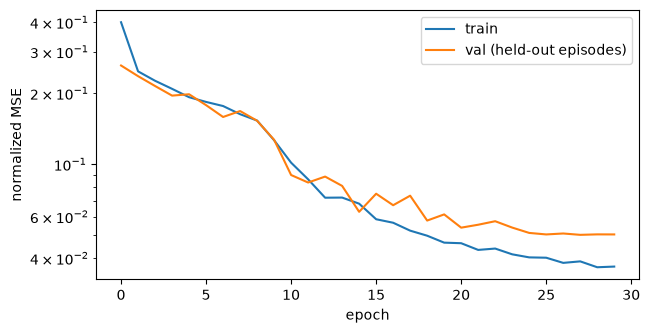

In [2]:
train_ds = TableTopDataset(DATA, episodes=range(0, 450), action_mode="delta")   # the textbook recipe: imitate the expert's raw per-step actions
val_ds = TableTopDataset(DATA, episodes=range(450, 500), action_mode="delta")
print(f"train frames {len(train_ds)}, val frames {len(val_ds)}; sample keys {list(train_ds[0].keys())}")
t0 = time.time()
net, log = train_bc(train_ds, val_ds)
print(f"trained in {time.time() - t0:.0f}s on {device}")
plt.figure(figsize=(7, 3.5)); plt.plot(log[:, 0], label="train"); plt.plot(log[:, 1], label="val (held-out episodes)")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("normalized MSE"); plt.legend(); plt.show()

In [3]:
env = TableTop(scene=SCENE, cameras=("front", "wrist"), image_size=(128, 128), seed=0)
policy = TorchPolicy(net, train_ds, device, env=env)
res = evaluate(env, policy, n_episodes=50, seed=50_000, record=3)
print(f"pixel BC success: {res['success']:.2f}  95% CI [{res['ci'][0]:.2f}, {res['ci'][1]:.2f}]  per task {res['per_task']}")
from vlacourse import showcase as sc
sc.watch(env, policy, seeds=[50_000 + i for i in range(4)], title="58 pixel BC: four new layouts")   # HD, embedded, outputs/*.mp4

pixel BC success: 0.76  95% CI [0.63, 0.86]  per task {'pick': 0.84, 'place': 0.68}


58 pixel BC: four new layouts: 3/4 successful


[True, False, True, True]

failed instructions: ['put the red cube in the green tray', 'pick up the red cube', 'pick up the red cube', 'put the red cube in the green tray', 'put the red cube in the green tray', 'pick up the red cube', 'put the red cube in the green tray', 'put the red cube in the green tray', 'put the red cube in the green tray', 'put the red cube in the green tray']


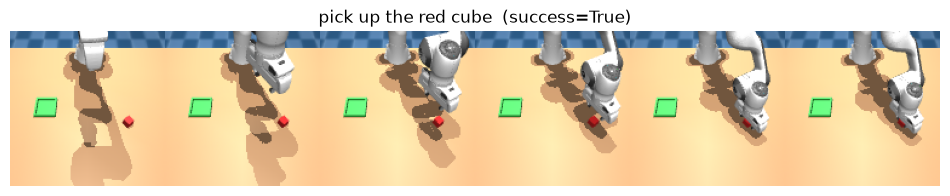

In [4]:
os.makedirs("checkpoints", exist_ok=True)
torch.save(net.state_dict(), "checkpoints/bc_pixels.pt")
fails = [e for e in res["episodes"] if not e["success"]]
print("failed instructions:", [e["instruction"] for e in fails][:10])
plt.figure(figsize=(12, 3)); plt.imshow(np.hstack(res["videos"][0][::max(1, len(res['videos'][0]) // 6)][:6])); plt.axis("off")
plt.title(res["episodes"][0]["instruction"] + f"  (success={res['episodes'][0]['success']})"); plt.show()